# Final MNIST Model Evaluation and Comparative Analysis
## Stage 4: Frozen models and the official test set
This standalone notebook performs the approved final evaluation of the saved Logistic Regression classifier and selected 100/100 dense Neural Network. Both were fitted using 54,000 training images; their choices were settled using 6,000 validation images before opening these test results.

The official 10,000-image MNIST test set was reserved throughout Stages 1-3. It now estimates performance on unseen examples from this benchmark. Keeping it separate reduces the optimistic bias that would arise from repeatedly choosing settings using test scores. These results do not establish performance on phone photographs or independently identified new writers.

**Frozen decision:** evaluate only `models/logistic_regression.joblib` and `models/neural_network.keras`. Do not retrain, tune, replace models, evaluate the rejected 50/50 trial, or change preprocessing after seeing results. `MNIST_Final_Project.ipynb` and its approved findings remain unchanged.

**Brief:** `Data Science Project.pdf`, page 3, model evaluation and comparison. This notebook stops after final evaluation and a concise summary; the technical report, presentation, publishing and demonstration are later phases.

## Classroom methods retained
Use short sequential cells, familiar `np`, `pd`, `plt`, `seaborn`, `reg_log`, `x` and `y` conventions, and labelled Pandas tables. Cell references are one-based notebook positions, including markdown/empty cells.

| Pattern | Original classroom evidence | Adaptation |
|---|---|---|
| Direct imports and plotting style | `linear regression.ipynb`, cells 1, 6 and 8 | Import only the analysis and loading tools used here |
| Pixel normalization | `Untitled19.ipynb`, cell 3 | Same float32/divide-by-255 rule on approved test images |
| Prediction and held-out comparison | `Bank_Data_Logistic_Regression (1).ipynb`, cells 8 and 17-20; `Untitled18.ipynb`, cell 8 | Load frozen models and predict the final test partition |
| Confusion tables and diagonal accuracy | Bank notebook, cells 10-12 and 18-20 | Extend binary tables to ten classes; no binary cutoff |
| Array persistence | `Untitled20.ipynb`, cells 8-9 | Save/reload ordered test predictions with integrity identifiers |
| Shape changes | `Untitled13.ipynb`, cells 16-17 and 46 | Reshape images into 784-feature views for Logistic Regression |

SHA-256 checks, model persistence, prediction caching, macro metrics, grouped bars and error-image grids are necessary additions already introduced or explained in this project. They do not introduce a new model or training method.

## 1. Environment and the existing local cache
Select the dedicated `mnist_project` interpreter, restart the kernel, and run cells in order. Set `KERAS_HOME` before importing TensorFlow/Keras. Verify the existing cached dataset hash before the required loader runs. No downloads or installations are needed.

The frozen-model record was written before final predictions. Subsequent reruns reuse saved, hash-identified predictions instead of calling the models again. This avoids unnecessary repeat test evaluation; it is a simple `if`/load-or-predict addition for reproducibility.

In [1]:
import os
import sys
import json
import time
import hashlib
import zipfile
import importlib.metadata

assert sys.version_info[:2] == (3, 11), 'Select the documented Python 3.11 kernel.'
project_dir = os.path.abspath(os.getcwd())
assert os.path.isfile(os.path.join(project_dir, 'MNIST_Final_Project.ipynb')), 'Open the notebook from the repository root.'
os.environ['KERAS_HOME'] = os.path.join(project_dir, '.keras')
os.environ['MPLCONFIGDIR'] = os.path.join(project_dir, '.cache', 'matplotlib')
results_dir = os.path.join(project_dir, 'results', 'stage4')
models_dir = os.path.join(project_dir, 'models')
dataset_path = os.path.join(os.environ['KERAS_HOME'], 'datasets', 'mnist.npz')
assert os.path.isfile(dataset_path)
assert os.path.isdir(results_dir)

print('Python executable:', sys.executable)
print('KERAS_HOME:', os.environ['KERAS_HOME'])

Python executable: <active Python interpreter>
KERAS_HOME: ./.keras


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
import tensorflow as tf
import joblib

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

seaborn.set()
versions = {name: importlib.metadata.version(name) for name in ['tensorflow', 'keras', 'numpy', 'pandas', 'scikit-learn', 'joblib', 'matplotlib', 'seaborn']}
for name in versions:
    print(name + ': ' + versions[name])

tensorflow: 2.21.0
keras: 3.15.1
numpy: 2.4.6
pandas: 3.1.0
scikit-learn: 1.9.1
joblib: 1.6.0
matplotlib: 3.11.2
seaborn: 0.13.2


## 2. Verify frozen model files and settings before inference
Only load the two named files within this trusted project's `models` directory. Verify SHA-256 against the records created during training and the pre-evaluation freeze record. Check the saved NN settings and native architecture before evaluating any test image.

Loading with `compile=False` prepares the selected Keras model for inference without recreating training machinery; it does not change the saved file. The native file's stored optimizer/loss configuration is separately checked. No `.fit`, new `.compile`, weight updates or parameter changes occur here.

In [3]:
with open(os.path.join(results_dir, 'frozen_models_before_evaluation.json'), encoding='utf-8') as file:
    frozen_before = json.load(file)
with open(os.path.join(project_dir, 'results', 'stage2', 'logistic_regression_run.json'), encoding='utf-8') as file:
    lr_run = json.load(file)
with open(os.path.join(project_dir, 'results', 'stage3', 'neural_network_run.json'), encoding='utf-8') as file:
    nn_run = json.load(file)
with open(os.path.join(project_dir, 'results', 'stage3', 'selected_settings.json'), encoding='utf-8') as file:
    selected_settings = json.load(file)

lr_path = os.path.realpath(os.path.join(models_dir, 'logistic_regression.joblib'))
nn_path = os.path.realpath(os.path.join(models_dir, 'neural_network.keras'))
assert os.path.dirname(lr_path) == os.path.realpath(models_dir)
assert os.path.dirname(nn_path) == os.path.realpath(models_dir)
with open(lr_path, 'rb') as file:
    lr_sha256_before = hashlib.sha256(file.read()).hexdigest()
with open(nn_path, 'rb') as file:
    nn_sha256_before = hashlib.sha256(file.read()).hexdigest()
with open(dataset_path, 'rb') as file:
    dataset_sha256 = hashlib.sha256(file.read()).hexdigest()
assert lr_sha256_before == lr_run['model_sha256'] == frozen_before['models']['logistic_regression.joblib']['sha256_before']
assert nn_sha256_before == nn_run['model_sha256']['neural_network.keras'] == frozen_before['models']['neural_network.keras']['sha256_before']
assert dataset_sha256 == lr_run['dataset_sha256'] == nn_run['dataset_sha256']
assert selected_settings == nn_run['selected_settings'] == frozen_before['neural_network_settings']
assert selected_settings['hidden_units_per_layer'] == 100
assert selected_settings['hidden_layers'] == 2
assert selected_settings['output_units'] == 10
with zipfile.ZipFile(nn_path) as native_model:
    native_config = json.loads(native_model.read('config.json'))
assert native_config['compile_config']['optimizer']['class_name'] == 'Adam'
assert np.isclose(native_config['compile_config']['optimizer']['config']['learning_rate'], selected_settings['learning_rate'])
assert native_config['compile_config']['loss'] == selected_settings['loss']
assert versions['scikit-learn'] == lr_run['versions']['scikit-learn']
assert versions['tensorflow'] == nn_run['versions']['tensorflow']
assert versions['keras'] == nn_run['versions']['keras']
print('Frozen Logistic Regression SHA-256:', lr_sha256_before)
print('Frozen selected Neural Network SHA-256:', nn_sha256_before)
print('Saved settings confirmed: two 100-unit ReLU hidden layers and ten softmax outputs.')

Frozen Logistic Regression SHA-256: d97566f2cbb699d3ec2f8f7ba2370314adab7b449788c2917863c65dbbac6379
Frozen selected Neural Network SHA-256: 04b9c0ac6dd5128127311aea2ddc400d601f282d250004914348e21b0a94ccde
Saved settings confirmed: two 100-unit ReLU hidden layers and ten softmax outputs.


In [4]:
reg_log = joblib.load(lr_path)
model = tf.keras.models.load_model(nn_path, compile=False)
assert reg_log.n_features_in_ == 784
assert np.array_equal(reg_log.classes_, np.arange(10))
for setting_name in ['C', 'solver', 'max_iter', 'tol', 'fit_intercept']:
    assert reg_log.get_params()[setting_name] == lr_run['settings'][setting_name]
assert model.input_shape == (None, 28, 28)
assert model.output_shape == (None, 10)
assert [layer.units for layer in model.layers if hasattr(layer, 'units')] == [100, 100, 10]
assert [layer.activation.__name__ for layer in model.layers if hasattr(layer, 'units')] == ['relu', 'relu', 'softmax']
assert model.count_params() == 89610

lr_weights_before = hashlib.sha256(reg_log.coef_.tobytes() + reg_log.intercept_.tobytes()).hexdigest()
nn_weights_before = hashlib.sha256(b''.join(weights.tobytes() for weights in model.get_weights())).hexdigest()
print('Both frozen models loaded successfully. No training is performed.')

Both frozen models loaded successfully. No training is performed.


## 3. Load the official test partition
Use the PDF's required Keras loader with the verified local cache. It returns both original partitions. Check their expected shapes and immediately discard training arrays; only the official 10,000 test images are used below. Their order is unchanged, with indices 0-9,999.

The same integer labels and same ordered examples will score both frozen models. This is the first approved final evaluation, not a new validation split.

In [5]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
assert x_train.shape == (60000, 28, 28)
assert y_train.shape == (60000,)
del x_train, y_train
assert x_test.shape == (10000, 28, 28)
assert y_test.shape == (10000,)
assert x_test.dtype == np.uint8
assert np.issubdtype(y_test.dtype, np.integer)
assert np.array_equal(np.unique(y_test), np.arange(10))
assert x_test.min() == 0 and x_test.max() == 255
test_indices = np.arange(10000)
raw_test_images_sha256 = hashlib.sha256(x_test.tobytes()).hexdigest()
test_labels_sha256 = hashlib.sha256(y_test.tobytes()).hexdigest()
print('Official test images:', x_test.shape, x_test.dtype)
print('Official test labels:', y_test.shape, y_test.dtype)
print('Digits:', np.unique(y_test))

Official test images: (10000, 28, 28) uint8
Official test labels: (10000,) uint8
Digits: [0 1 2 3 4 5 6 7 8 9]


## 4. Apply the unchanged preprocessing
Convert raw pixels to float32 and divide by 255 exactly once, following `Untitled19.ipynb`, cell 3. Keep shape (10000,28,28) for the network's existing Flatten layer. Reshape a view to (10000,784) for Logistic Regression, following the classroom reshape pattern.

No scaler is fitted and no label is normalized. Both models receive identical normalized pixel values. Only one normalized image array is retained; the flattened array shares its storage.

In [6]:
test_inputs = x_test.astype(np.float32)
test_inputs /= 255.
x = test_inputs.reshape(10000, 784)
y = y_test
assert test_inputs.dtype == x.dtype == np.float32
assert test_inputs.shape == (10000, 28, 28)
assert x.shape == (10000, 784)
assert np.shares_memory(x, test_inputs)
assert 0 <= test_inputs.min() <= test_inputs.max() <= 1
assert np.isfinite(test_inputs).all()
print('Neural Network inputs:', test_inputs.shape)
print('Logistic Regression inputs:', x.shape)
print('Normalized range:', test_inputs.min(), test_inputs.max())
print('Normalized image storage (MiB): {0:.2f}'.format(test_inputs.nbytes / 1024**2))
print('Flattened view shares storage:', np.shares_memory(x, test_inputs))

Neural Network inputs: (10000, 28, 28)
Logistic Regression inputs: (10000, 784)
Normalized range: 0.0 1.0
Normalized image storage (MiB): 29.91
Flattened view shares storage: True


## 5. Predict with frozen Logistic Regression once
For each class k the classifier computes a linear score `z_k = w_k dot x + b_k`. Multinomial softmax converts scores into probabilities, and `.predict()` returns the digit with the largest score/probability. Its learned coefficients are loaded, not fitted again.

**Classroom relationship:** `Bank_Data_Logistic_Regression (1).ipynb`, cells 8 and 17-19, predicts on held-out inputs. This is the existing Scikit-learn multiclass adaptation.

Save predictions immediately. On later reruns, load the saved predictions only after checking the frozen model hash, dataset hash, ordered indices and true labels. This caching is an integrity/reproducibility addition, not model selection.

In [7]:
lr_predictions_path = os.path.join(results_dir, 'logistic_test_predictions.npz')
if os.path.isfile(lr_predictions_path):
    with np.load(lr_predictions_path, allow_pickle=False) as saved:
        assert saved['model_sha256'].item() == lr_sha256_before
        assert saved['dataset_sha256'].item() == dataset_sha256
        assert np.array_equal(saved['test_indices'], test_indices)
        assert np.array_equal(saved['actual'], y)
        logistic_predictions = saved['predicted']
        lr_prediction_created_utc = saved['created_utc'].item()
    lr_prediction_source = 'Reused frozen saved predictions'
else:
    logistic_predictions = reg_log.predict(x)
    lr_prediction_created_utc = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
    np.savez_compressed(lr_predictions_path, test_indices=test_indices, actual=y, predicted=logistic_predictions,
                        model_sha256=lr_sha256_before, dataset_sha256=dataset_sha256, created_utc=lr_prediction_created_utc)
    lr_prediction_source = 'Computed once from frozen model'
assert logistic_predictions.shape == (10000,)
assert np.isin(logistic_predictions, np.arange(10)).all()
print(lr_prediction_source)
print('Logistic Regression predictions:', logistic_predictions.shape)

Computed once from frozen model
Logistic Regression predictions: (10000,)


## 6. Predict with the selected Neural Network once
The fixed network applies two learned ReLU hidden layers before its ten-output softmax. A neuron forms a weighted sum plus bias; ReLU is `max(0,z)`. Softmax is `exp(z_k) / sum(exp(z_j))`. Hidden nonlinearities allow more flexible relationships between pixels than a linear classifier.

`model.predict` returns ten probability scores for each image, in batches of 100. `np.argmax(..., axis=1)` returns their largest-position digit label. These scores are not calibrated guarantees. Do not call `.evaluate()` for another inference pass: the saved predictions supply all required metrics.

**Classroom sources:** `Untitled18.ipynb`, cells 4-8, demonstrates learned weights and prediction; `Untitled19.ipynb`, cells 7-11, demonstrates the dense softmax model and held-out evaluation. Batched prediction and argmax are the ten-class additions already used in Stage 3.

In [8]:
nn_predictions_path = os.path.join(results_dir, 'neural_test_predictions.npz')
if os.path.isfile(nn_predictions_path):
    with np.load(nn_predictions_path, allow_pickle=False) as saved:
        assert saved['model_sha256'].item() == nn_sha256_before
        assert saved['dataset_sha256'].item() == dataset_sha256
        assert np.array_equal(saved['test_indices'], test_indices)
        assert np.array_equal(saved['actual'], y)
        neural_probabilities = saved['probabilities']
        neural_predictions = saved['predicted']
        nn_prediction_created_utc = saved['created_utc'].item()
    nn_prediction_source = 'Reused frozen saved predictions'
else:
    neural_probabilities = model.predict(test_inputs, batch_size=100, verbose=0)
    neural_predictions = np.argmax(neural_probabilities, axis=1)
    nn_prediction_created_utc = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
    np.savez_compressed(nn_predictions_path, test_indices=test_indices, actual=y, predicted=neural_predictions,
                        probabilities=neural_probabilities, model_sha256=nn_sha256_before,
                        dataset_sha256=dataset_sha256, created_utc=nn_prediction_created_utc)
    nn_prediction_source = 'Computed once from frozen model'
assert neural_probabilities.shape == (10000, 10)
assert neural_predictions.shape == (10000,)
assert np.isfinite(neural_probabilities).all()
assert (neural_probabilities >= 0).all() and (neural_probabilities <= 1).all()
assert np.allclose(neural_probabilities.sum(axis=1), 1, atol=1e-5)
assert np.array_equal(np.argmax(neural_probabilities, axis=1), neural_predictions)
assert np.isin(neural_predictions, np.arange(10)).all()
print(nn_prediction_source)
print('Neural Network predictions:', neural_predictions.shape)

Computed once from frozen model
Neural Network predictions: (10000,)


## 7. Explain and calculate evaluation metrics
For each digit, treat that digit as positive and the other nine as negative:

- **TP:** correctly predicted examples of the digit.
- **FP:** other digits incorrectly predicted as this digit.
- **FN:** examples of this digit incorrectly predicted as another digit.
- **Accuracy = number correct / N**, where N=10,000.
- **Precision = TP / (TP + FP):** how often predictions of this digit are correct.
- **Recall = TP / (TP + FN):** how many actual examples of this digit are found.
- **F1 = 2TP / (2TP + FP + FN):** combines precision and recall.
- **Macro metric = (metric for digit 0 + ... + metric for digit 9) / 10:** every digit receives equal weight. Macro F1 averages per-class F1 values; it is not F1 computed from macro precision and recall.

Use `zero_division=0` for undefined ratios. Per-class support is the number of true examples of a digit. **Classroom evidence:** bank notebook cells 10-12 and 18-21 supplies accuracy and misclassification. Precision/recall/F1, macro averaging and classification reports are required multiclass additions retained from Stages 2-3.

In [9]:
lr_metrics = {
    'accuracy': accuracy_score(y, logistic_predictions),
    'macro_precision': precision_score(y, logistic_predictions, labels=range(10), average='macro', zero_division=0),
    'macro_recall': recall_score(y, logistic_predictions, labels=range(10), average='macro', zero_division=0),
    'macro_f1': f1_score(y, logistic_predictions, labels=range(10), average='macro', zero_division=0)
}
lr_correct = int(np.sum(logistic_predictions == y))
lr_incorrect = int(np.sum(logistic_predictions != y))
lr_report = classification_report(y, logistic_predictions, labels=range(10), output_dict=True, zero_division=0)
print('Logistic Regression test metrics:', lr_metrics)
print('Correct:', lr_correct, 'Incorrect:', lr_incorrect)

Logistic Regression test metrics: {'accuracy': 0.9254, 'macro_precision': 0.9244319002938894, 'macro_recall': 0.9243477008476868, 'macro_f1': 0.9243025894985898}
Correct: 9254 Incorrect: 746


In [10]:
nn_metrics = {
    'accuracy': accuracy_score(y, neural_predictions),
    'macro_precision': precision_score(y, neural_predictions, labels=range(10), average='macro', zero_division=0),
    'macro_recall': recall_score(y, neural_predictions, labels=range(10), average='macro', zero_division=0),
    'macro_f1': f1_score(y, neural_predictions, labels=range(10), average='macro', zero_division=0)
}
nn_correct = int(np.sum(neural_predictions == y))
nn_incorrect = int(np.sum(neural_predictions != y))
nn_report = classification_report(y, neural_predictions, labels=range(10), output_dict=True, zero_division=0)
print('Neural Network test metrics:', nn_metrics)
print('Correct:', nn_correct, 'Incorrect:', nn_incorrect)

Neural Network test metrics: {'accuracy': 0.9753, 'macro_precision': 0.9751814850185851, 'macro_recall': 0.9749538646239934, 'macro_f1': 0.9750451010715324}
Correct: 9753 Incorrect: 247


## 8. Per-class precision, recall, F1 and support
Inspect every digit rather than relying only on the overall accuracy. The reports also give macro averages and support-weighted averages. The same 10,000 labels score both models.

In [11]:
print('LOGISTIC REGRESSION: OFFICIAL TEST SET')
print(classification_report(y, logistic_predictions, labels=range(10), digits=4, zero_division=0))
print('SELECTED NEURAL NETWORK: OFFICIAL TEST SET')
print(classification_report(y, neural_predictions, labels=range(10), digits=4, zero_division=0))

LOGISTIC REGRESSION: OFFICIAL TEST SET
              precision    recall  f1-score   support

           0     0.9541    0.9765    0.9652       980
           1     0.9611    0.9789    0.9699      1135
           2     0.9315    0.8953    0.9130      1032
           3     0.9005    0.9139    0.9071      1010
           4     0.9369    0.9379    0.9374       982
           5     0.8921    0.8711    0.8815       892
           6     0.9392    0.9520    0.9456       958
           7     0.9366    0.9193    0.9278      1028
           8     0.8783    0.8819    0.8801       974
           9     0.9140    0.9167    0.9154      1009

    accuracy                         0.9254     10000
   macro avg     0.9244    0.9243    0.9243     10000
weighted avg     0.9253    0.9254    0.9252     10000

SELECTED NEURAL NETWORK: OFFICIAL TEST SET
              precision    recall  f1-score   support

           0     0.9807    0.9857    0.9832       980
           1     0.9885    0.9885    0.9885      1

## 9. Confusion matrices
Rows are actual digits and columns are predicted digits. The diagonal counts correct predictions; an off-diagonal entry counts a particular confusion. Each matrix must sum to 10,000, and its diagonal divided by 10,000 must equal accuracy.

This extends the labelled tables and diagonal calculation in `Bank_Data_Logistic_Regression (1).ipynb`, cells 10-12 and 18-20. We keep the ten-class Scikit-learn/Seaborn adaptation used in Stages 2-3.

In [12]:
lr_cm = confusion_matrix(y, logistic_predictions, labels=range(10))
nn_cm = confusion_matrix(y, neural_predictions, labels=range(10))
assert lr_cm.shape == nn_cm.shape == (10, 10)
assert lr_cm.sum() == nn_cm.sum() == 10000
assert np.trace(lr_cm) == lr_correct
assert np.trace(nn_cm) == nn_correct
assert np.isclose(np.trace(lr_cm) / 10000, lr_metrics['accuracy'])
assert np.isclose(np.trace(nn_cm) / 10000, nn_metrics['accuracy'])
lr_cm_df = pd.DataFrame(lr_cm, index=range(10), columns=range(10))
nn_cm_df = pd.DataFrame(nn_cm, index=range(10), columns=range(10))
lr_cm_df.index.name = nn_cm_df.index.name = 'Actual digit'
lr_cm_df.columns.name = nn_cm_df.columns.name = 'Predicted digit'
print('Logistic Regression confusion matrix:')
print(lr_cm_df)
print('Neural Network confusion matrix:')
print(nn_cm_df)

Logistic Regression confusion matrix:
Predicted digit    0     1    2    3    4    5    6    7    8    9
Actual digit                                                      
0                957     0    2    3    0   10    3    4    1    0
1                  0  1111    4    2    0    2    3    2   11    0
2                  6     9  924   17   11    4   12    9   36    4
3                  4     1   16  923    0   26    3   10   19    8
4                  1     3    5    3  921    0   10    4    8   27
5                  9     2    2   38    8  777   16    5   32    3
6                  8     3    7    3    7   15  912    2    1    0
7                  1     7   25    5    5    1    0  945    5   34
8                  8    12    7   21    7   28   12    9  859   11
9                  9     8    0   10   24    8    0   19    6  925
Neural Network confusion matrix:
Predicted digit    0     1     2    3    4    5    6     7    8    9
Actual digit                                            

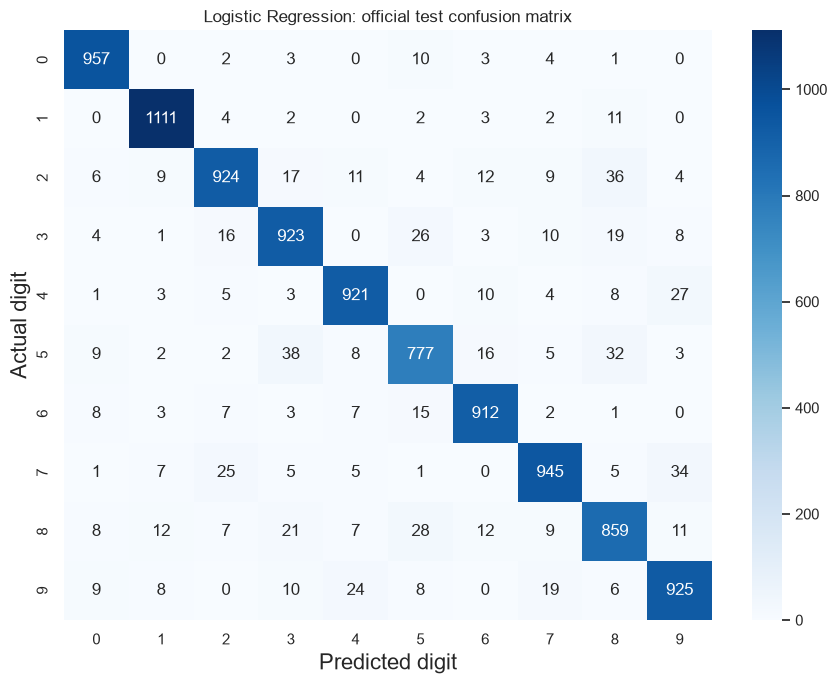

In [13]:
plt.figure(figsize=(9, 7))
seaborn.heatmap(lr_cm_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted digit', fontsize=16)
plt.ylabel('Actual digit', fontsize=16)
plt.title('Logistic Regression: official test confusion matrix')
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'logistic_test_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

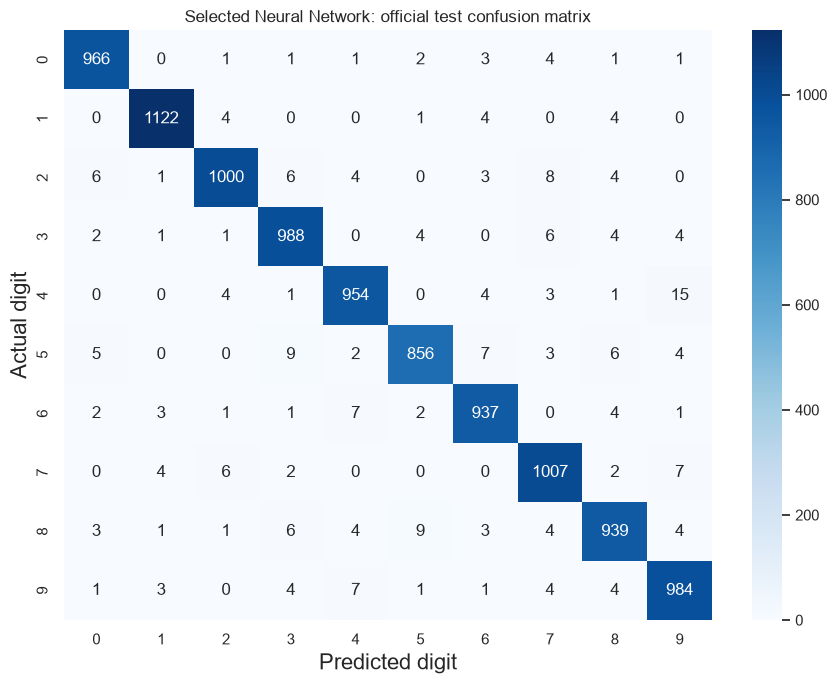

In [14]:
plt.figure(figsize=(9, 7))
seaborn.heatmap(nn_cm_df, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted digit', fontsize=16)
plt.ylabel('Actual digit', fontsize=16)
plt.title('Selected Neural Network: official test confusion matrix')
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'neural_test_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

## 10. Final comparison and recorded training times
Read fit times from the approved Stage 2 and Stage 3 records. No model is trained in this notebook. Distinguish the selected network's fit time from the sum of both neural-network candidates.

Timing scopes differ: each NN fit included validation after every epoch; Logistic Regression's fit excluded subsequent validation prediction. These are single CPU-run measurements and do not prove a general or definitive training-speed advantage.

In [15]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Selected Neural Network (100/100)'],
    'Test accuracy': [lr_metrics['accuracy'], nn_metrics['accuracy']],
    'Macro precision': [lr_metrics['macro_precision'], nn_metrics['macro_precision']],
    'Macro recall': [lr_metrics['macro_recall'], nn_metrics['macro_recall']],
    'Macro F1': [lr_metrics['macro_f1'], nn_metrics['macro_f1']],
    'Correct predictions': [lr_correct, nn_correct],
    'Incorrect predictions': [lr_incorrect, nn_incorrect],
    'Recorded training time (seconds)': [lr_run['training_time_seconds'], nn_run['selected_training_time_seconds']]
})
print(comparison.to_string(index=False))
print('Total fit time for both NN candidates (seconds): {0:.6f}'.format(nn_run['total_nn_fit_time_seconds']))

                            Model  Test accuracy  Macro precision  Macro recall  Macro F1  Correct predictions  Incorrect predictions  Recorded training time (seconds)
              Logistic Regression         0.9254         0.924432      0.924348  0.924303                 9254                    746                         52.845251
Selected Neural Network (100/100)         0.9753         0.975181      0.974954  0.975045                 9753                    247                         23.330180
Total fit time for both NN candidates (seconds): 47.077246


## 11. Side-by-side performance comparison
Use Matplotlib bars, labels and legends. The four test scores use a 0-1 axis so differences are not exaggerated. Recorded fit times have a separate seconds axis and the scope limitation above. Grouped bars and subplot arrangement are small visualization additions to the lecturer's plotting style (`linear regression.ipynb`, cells 6 and 8).

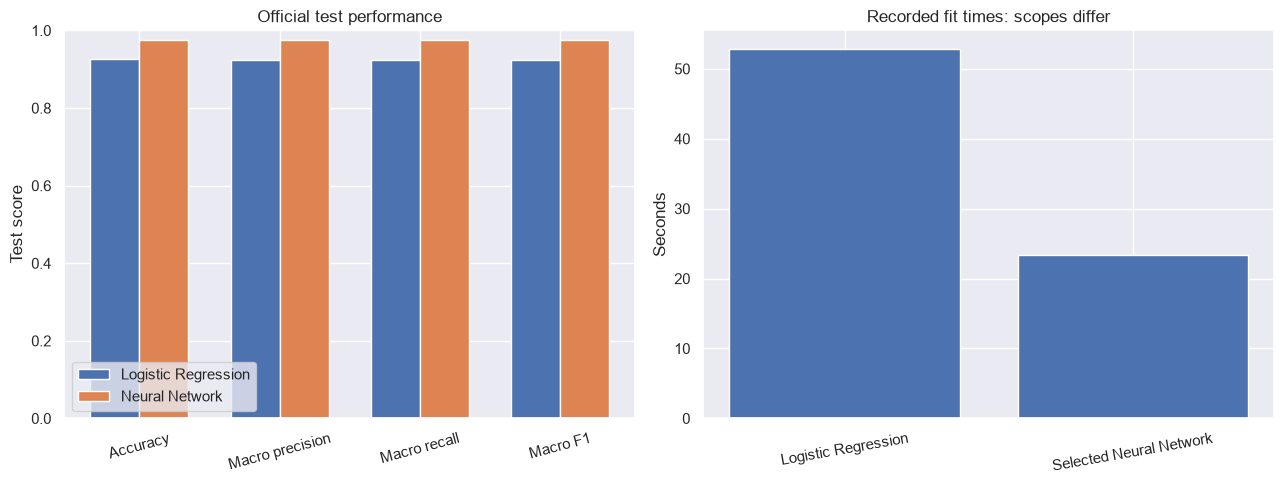

In [16]:
metric_positions = np.arange(4)
metric_names = ['Accuracy', 'Macro precision', 'Macro recall', 'Macro F1']
lr_scores = [lr_metrics[name] for name in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']]
nn_scores = [nn_metrics[name] for name in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']]
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.bar(metric_positions - 0.175, lr_scores, width=0.35, label='Logistic Regression')
plt.bar(metric_positions + 0.175, nn_scores, width=0.35, label='Neural Network')
plt.xticks(metric_positions, metric_names, rotation=15)
plt.ylim(0, 1)
plt.ylabel('Test score')
plt.title('Official test performance')
plt.legend(loc='lower left')
plt.subplot(1, 2, 2)
plt.bar(['Logistic Regression', 'Selected Neural Network'], [lr_run['training_time_seconds'], nn_run['selected_training_time_seconds']])
plt.xticks(rotation=10)
plt.ylabel('Seconds')
plt.title('Recorded fit times: scopes differ')
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'final_model_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

## 12. Inspect errors after freezing all choices
Display the first ten wrong predictions in ascending test-index order for each model. This fixed rule avoids selecting only dramatic examples. Show original raw images, their correct digit and the model's predicted digit.

Image display follows the PDF's sample-image code and Stage 1's Matplotlib grid. This is final error analysis, not a prediction demonstration or a basis for further tuning. Do not modify labels or models based on these images.

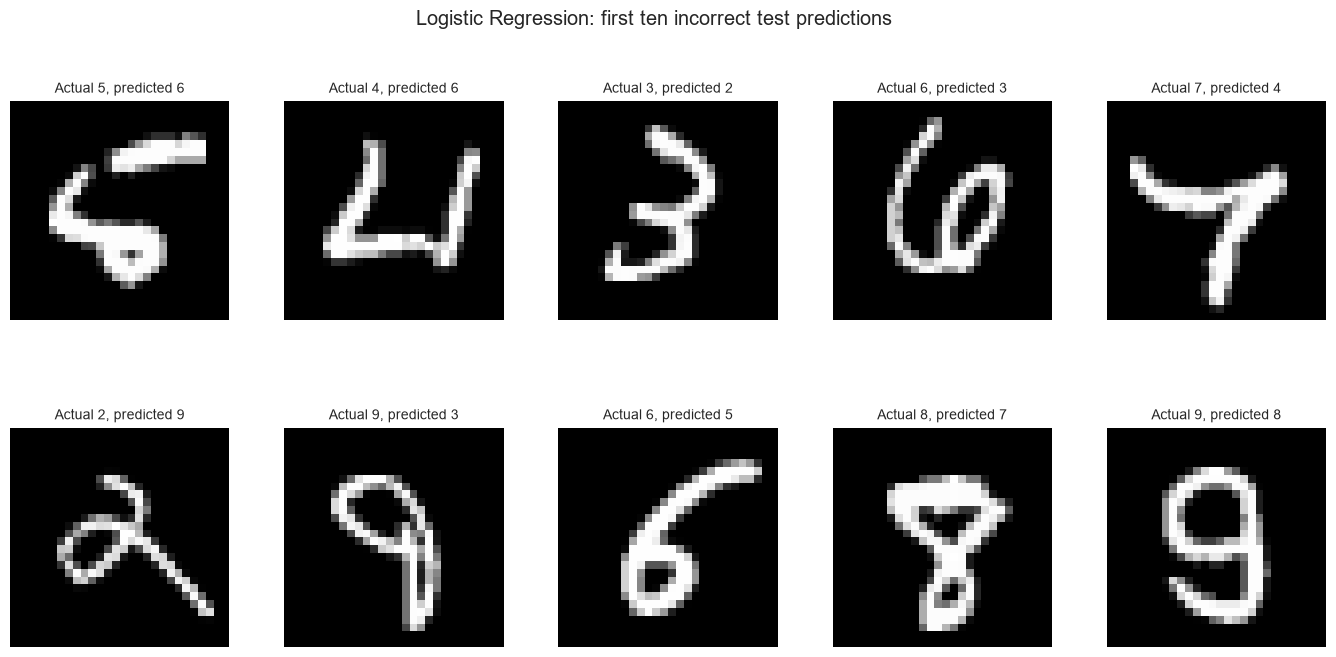

In [17]:
lr_wrong_indices = np.where(logistic_predictions != y)[0]
plt.close('all')
plt.figure(figsize=(14, 7))
for i, image_index in enumerate(lr_wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[image_index], cmap='gray', vmin=0, vmax=255)
    plt.title('Actual {0}, predicted {1}'.format(y[image_index], logistic_predictions[image_index]), fontsize=10)
    plt.axis('off')
plt.suptitle('Logistic Regression: first ten incorrect test predictions')
plt.subplots_adjust(left=0.04, right=0.98, bottom=0.04, top=0.88, wspace=0.25, hspace=0.25)
plt.savefig(os.path.join(results_dir, 'logistic_test_errors.png'), dpi=150, bbox_inches='tight')
plt.show()

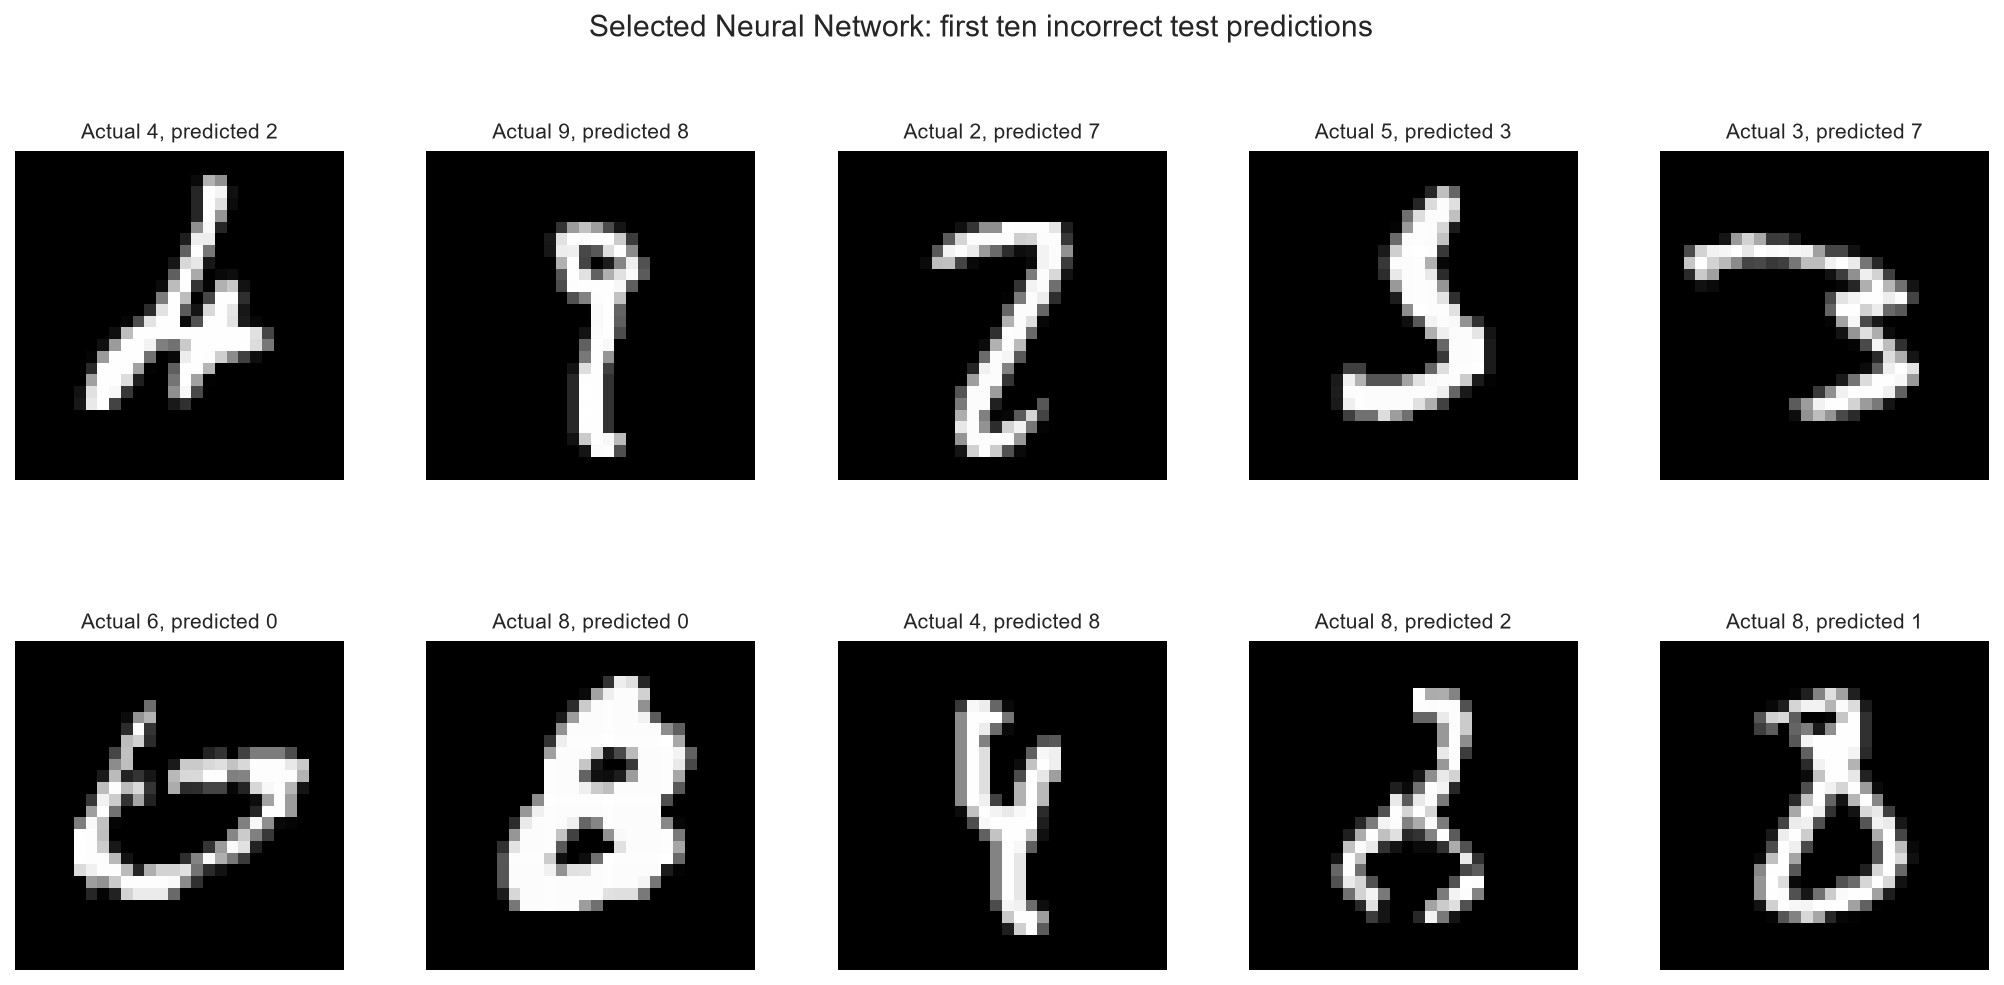

In [18]:
nn_wrong_indices = np.where(neural_predictions != y)[0]
plt.close('all')
plt.figure(figsize=(14, 7))
for i, image_index in enumerate(nn_wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[image_index], cmap='gray', vmin=0, vmax=255)
    plt.title('Actual {0}, predicted {1}'.format(y[image_index], neural_predictions[image_index]), fontsize=10)
    plt.axis('off')
plt.suptitle('Selected Neural Network: first ten incorrect test predictions')
plt.subplots_adjust(left=0.04, right=0.98, bottom=0.04, top=0.88, wspace=0.25, hspace=0.25)
plt.savefig(os.path.join(results_dir, 'neural_test_errors.png'), dpi=150, bbox_inches='tight')
plt.show()

## 13. Count frequent confusions
Use familiar loops, conditions and list append to collect the off-diagonal counts, then sort a small Pandas table. `Untitled20.ipynb`, cell 3, demonstrates the loop/condition/append pattern. Ranking confusion pairs is a necessary error-analysis addition. Counts, not visual impressions, establish which confusions are most frequent.

In [19]:
confusion_rows = []
for model_name, matrix in [('Logistic Regression', lr_cm), ('Neural Network', nn_cm)]:
    for actual_digit in range(10):
        for predicted_digit in range(10):
            if actual_digit != predicted_digit:
                confusion_rows.append({'Model': model_name, 'Actual digit': actual_digit,
                                       'Predicted digit': predicted_digit, 'Count': int(matrix[actual_digit, predicted_digit])})
confusion_pairs = pd.DataFrame(confusion_rows).sort_values(
    ['Count', 'Actual digit', 'Predicted digit'], ascending=[False, True, True])
print('Most frequent Logistic Regression confusions:')
print(confusion_pairs[confusion_pairs['Model'] == 'Logistic Regression'].head(5).to_string(index=False))
print('Most frequent Neural Network confusions:')
print(confusion_pairs[confusion_pairs['Model'] == 'Neural Network'].head(5).to_string(index=False))

Most frequent Logistic Regression confusions:
              Model  Actual digit  Predicted digit  Count
Logistic Regression             5                3     38
Logistic Regression             2                8     36
Logistic Regression             7                9     34
Logistic Regression             5                8     32
Logistic Regression             8                5     28
Most frequent Neural Network confusions:
         Model  Actual digit  Predicted digit  Count
Neural Network             4                9     15
Neural Network             5                3      9
Neural Network             8                5      9
Neural Network             2                7      8
Neural Network             5                6      7


## Observations from the actual test errors

Logistic Regression's five largest off-diagonal counts are actual **5 predicted as 3 (38)**, **2 as 8 (36)**, **7 as 9 (34)**, **5 as 8 (32)** and **8 as 5 (28)**. The selected network's largest are **4 as 9 (15)**, **5 as 3 (9)**, **8 as 5 (9)** and **2 as 7 (8)**; several other pairs have seven errors. Rows are true digits and columns are predictions, so these are directional counts, not symmetric pairs. Raw counts also depend on each digit's support; the per-class reports give recall and precision for comparison.

The images above are the first ten errors in original test order for each model, rather than specially chosen examples. Their original indices are retained in the saved prediction/error records. For example, the first Logistic Regression error (index 8, actual 5, predicted 6) has a curled lower stroke. In the network examples, index 445 (actual 6, predicted 0) has a broad closed lower loop, while index 320 (actual 9, predicted 8) has a loop and a long lower stroke. Such shapes suggest possible ambiguity from loops, incomplete strokes and different handwriting styles. These visual interpretations are hypotheses, not proof of the models' internal reasoning. The displayed examples need not belong to the most frequent confusion pairs.

These observations explain errors after final evaluation. They were not used to change preprocessing, select another model or tune settings.


## 14. A real per-class mathematical example
Take digit **8**, chosen here before results were inspected. Its row sum gives support; its diagonal is TP. Subtract TP from the column sum for FP and from the row sum for FN. Calculate precision, recall and F1 from those counts, linking the formulas to actual results.

In [20]:
digit = 8
example_rows = []
for model_name, matrix in [('Logistic Regression', lr_cm), ('Neural Network', nn_cm)]:
    tp = int(matrix[digit, digit])
    fp = int(matrix[:, digit].sum() - tp)
    fn = int(matrix[digit, :].sum() - tp)
    example_rows.append({'Model': model_name, 'Digit': digit, 'TP': tp, 'FP': fp, 'FN': fn,
                         'Support': tp + fn, 'Precision': tp / (tp + fp) if tp + fp else 0,
                         'Recall': tp / (tp + fn) if tp + fn else 0,
                         'F1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0})
metric_examples = pd.DataFrame(example_rows)
print(metric_examples.to_string(index=False))

              Model  Digit  TP  FP  FN  Support  Precision   Recall       F1
Logistic Regression      8 859 119 115      974   0.878323 0.881930 0.880123
     Neural Network      8 939  30  35      974   0.969040 0.964066 0.966547


## 15. Save final results and verify immutability
Save comparison/metric tables, full classification reports, confusion matrices, error indices, formula examples and a reproducible evaluation record. Predictions were already saved immediately after the only inference pass per model.

Verify both file hashes and in-memory weight fingerprints after evaluation. This establishes unchanged saved artifacts and unchanged learned weights. Earlier results and the main training notebook are not written. These hashes and execution records are integrity additions requested for the final evaluation.

In [21]:
with open(lr_path, 'rb') as file:
    lr_sha256_after = hashlib.sha256(file.read()).hexdigest()
with open(nn_path, 'rb') as file:
    nn_sha256_after = hashlib.sha256(file.read()).hexdigest()
assert lr_sha256_after == lr_sha256_before
assert nn_sha256_after == nn_sha256_before
assert hashlib.sha256(reg_log.coef_.tobytes() + reg_log.intercept_.tobytes()).hexdigest() == lr_weights_before
assert hashlib.sha256(b''.join(weights.tobytes() for weights in model.get_weights())).hexdigest() == nn_weights_before
with open(os.path.join(project_dir, 'results', 'stage3', 'selected_settings.json'), 'rb') as file:
    assert hashlib.sha256(file.read()).hexdigest() == frozen_before['stage3_settings_sha256']

comparison.to_csv(os.path.join(results_dir, 'final_model_comparison.csv'), index=False)
lr_cm_df.to_csv(os.path.join(results_dir, 'logistic_test_confusion_matrix.csv'))
nn_cm_df.to_csv(os.path.join(results_dir, 'neural_test_confusion_matrix.csv'))
report_rows = [str(i) for i in range(10)] + ['macro avg', 'weighted avg']
pd.DataFrame(lr_report).T.loc[report_rows].to_csv(os.path.join(results_dir, 'logistic_classification_report.csv'), index_label='digit_or_average')
pd.DataFrame(nn_report).T.loc[report_rows].to_csv(os.path.join(results_dir, 'neural_classification_report.csv'), index_label='digit_or_average')
with open(os.path.join(results_dir, 'logistic_classification_report.txt'), 'w', encoding='utf-8') as file:
    file.write(classification_report(y, logistic_predictions, labels=range(10), digits=6, zero_division=0))
with open(os.path.join(results_dir, 'neural_classification_report.txt'), 'w', encoding='utf-8') as file:
    file.write(classification_report(y, neural_predictions, labels=range(10), digits=6, zero_division=0))
confusion_pairs.to_csv(os.path.join(results_dir, 'confusion_pairs.csv'), index=False)
metric_examples.to_csv(os.path.join(results_dir, 'digit_8_metric_example.csv'), index=False)
np.savez(os.path.join(results_dir, 'misclassified_test_indices.npz'), logistic=lr_wrong_indices, neural=nn_wrong_indices)
metrics = {'Logistic Regression': dict(lr_metrics, correct=lr_correct, incorrect=lr_incorrect),
           'Selected Neural Network': dict(nn_metrics, correct=nn_correct, incorrect=nn_incorrect)}
with open(os.path.join(results_dir, 'test_metrics.json'), 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)

evaluation_record = {
    'stage': 'Stage 4: final official MNIST test evaluation; no further model selection',
    'completed_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
    'python_executable': sys.executable, 'python_version': sys.version.split()[0], 'versions': versions,
    'dataset_cache': dataset_path, 'dataset_sha256': dataset_sha256,
    'raw_test_images_sha256': raw_test_images_sha256, 'test_labels_sha256': test_labels_sha256,
    'test_indices': 'Original order 0 through 9999; identical for both models',
    'test_examples': int(y.size), 'raw_image_shape': list(x_test.shape),
    'preprocessing': 'uint8 pixels -> float32 -> divide by 255 in place; NN (10000,28,28); LR shared view (10000,784); integer labels unchanged',
    'model_hashes_before': {'logistic_regression.joblib': lr_sha256_before, 'neural_network.keras': nn_sha256_before},
    'model_hashes_after': {'logistic_regression.joblib': lr_sha256_after, 'neural_network.keras': nn_sha256_after},
    'in_memory_weight_fingerprints_unchanged': True,
    'selected_nn_settings': selected_settings,
    'prediction_records': {'logistic': {'source': lr_prediction_source, 'created_utc': lr_prediction_created_utc},
                           'neural': {'source': nn_prediction_source, 'created_utc': nn_prediction_created_utc}},
    'test_metrics': metrics, 'comparison': comparison.to_dict(orient='records'),
    'classification_reports': {'logistic': lr_report, 'neural': nn_report},
    'confusion_matrices': {'logistic': lr_cm.tolist(), 'neural': nn_cm.tolist()},
    'recorded_training_times_seconds': {'logistic_regression': lr_run['training_time_seconds'],
                                      'selected_neural_network': nn_run['selected_training_time_seconds'],
                                      'both_nn_candidates_total': nn_run['total_nn_fit_time_seconds']},
    'training_time_limitation': 'NN fits include validation during epochs; LR fit excludes subsequent validation. Single runs do not establish a definitive training-speed ranking.',
    'thread_environment': {name: os.environ.get(name) for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'TF_NUM_INTRAOP_THREADS', 'TF_NUM_INTEROP_THREADS']},
    'error_image_selection': 'First ten incorrect indices in ascending original test order for each model',
    'no_retraining_or_tuning': True, 'rejected_50_unit_model_tested': False
}
with open(os.path.join(results_dir, 'evaluation_record.json'), 'w', encoding='utf-8') as file:
    json.dump(evaluation_record, file, indent=2)
print('Final results saved. Frozen files, settings and learned weights remain unchanged.')

Final results saved. Frozen files, settings and learned weights remain unchanged.


## Final findings and conclusions

Both frozen models evaluated the same 10,000 official test images in their original order. All 21 evaluation code cells executed successfully using the dedicated `mnist_project` interpreter. The selected network was confirmed as **Flatten → Dense(100, ReLU) → Dense(100, ReLU) → Dense(10, Softmax)**, with 89,610 parameters and saved settings matching Stage 3.

| Model | Test accuracy | Macro precision | Macro recall | Macro F1 | Correct | Incorrect | Recorded fit time (s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.925400 | 0.924432 | 0.924348 | 0.924303 | 9,254 | 746 | 52.845251 |
| Selected Neural Network (100/100) | 0.975300 | 0.975181 | 0.974954 | 0.975045 | 9,753 | 247 | 23.330180 |

The selected network achieved **97.53% accuracy**, compared with **92.54%** for Logistic Regression: a difference of **4.99 percentage points** and **499 fewer incorrect predictions**. It also had higher macro precision, recall and F1. This is the final test comparison, distinct from Stage 3's validation-only selection. The 50/50 network was not tested here. No model choice or setting was changed after observing test results.

Logistic Regression computes a weighted sum plus an intercept for each class and chooses the largest class score. The network applies learned weights, biases and ReLU transformations before Softmax produces ten probabilities; `argmax` selects the largest. Its nonlinear hidden layers can represent more flexible combinations of pixel patterns. That is a plausible explanation for its stronger result, although this comparison does not isolate architecture from differences in optimization and regularization or prove the cause of individual errors.

For a concrete statistical example, digit 8 has 974 true test examples. Logistic Regression has TP = 859, FP = 119 and FN = 115, giving precision = 859/978 = 0.878323, recall = 859/974 = 0.881930 and F1 = 1718/1952 = 0.880123. The network has TP = 939, FP = 30 and FN = 35, giving precision = 939/969 = 0.969040, recall = 939/974 = 0.964066 and F1 = 1878/1943 = 0.966547. Macro metrics average the ten individual digit scores equally. Both confusion matrices sum to 10,000 and their diagonals sum to the correct-prediction counts above.

The original training times are reused, with no new fitting: Logistic Regression **52.845251 s** and selected network **23.330180 s**. Training both network candidates previously took **47.077246 s** in total. Network fitting included validation during each epoch; the Logistic Regression fit timer excluded later validation predictions. These single measurements have different scopes and do not establish a definitive training-speed advantage.

Keeping the test set separate until model selection was finished makes this an assessment on previously unused examples rather than an assessment optimized by repeated tuning. It estimates generalization to this held-out MNIST sample, not a guarantee for all real handwriting or other datasets.

Verification independently reconstructed both confusion matrices and every per-class, macro and weighted metric from the saved ordered predictions. Frozen model hashes and in-memory learned-weight fingerprints matched before and after evaluation. All 68 protected original files, including the main project notebook, prior models/results, dataset cache and classroom notebooks, remained unchanged. There were no notebook cell errors. A Windows command-length error in notebook authoring was resolved by using a local helper; a post-execution helper typo (`lo_report` instead of `lr_report`) was corrected and saved outputs verified without repeating model inference. Error-grid labels were simplified and plots rerendered using saved predictions only. A non-interactive plotting helper emitted an expected `show()` warning; its saved image was verified.

Both models made one prediction pass each, with predictions saved immediately. Subsequent checks and plot corrections used these saved records. The evaluation ran under an offline network guard and loaded the hash-verified project-local cache. Results, full reports, figures, prediction records, software versions and frozen SHA-256 hashes are in `results/stage4`. Necessary additions beyond classroom examples (macro metrics, persistence/integrity checks and prediction caching) are explained in the methods cells.

**Stage 4 is complete.** The original Stages 1–3 notebook and recorded results are unchanged. Technical reporting, publication, presentation and demonstration remain pending separate approval.


## Stop after Stage 4
The final test results are an assessment of the already selected frozen models. No setting is changed using the error analysis. Do not evaluate the rejected candidate or tune against these outcomes.

The technical report, GitHub publishing, presentation and final prediction demonstration remain unstarted and require the student's next approval.